In [490]:
%pip install "meteostat>=2.1.5"
# Import Meteostat library
import meteostat as ms
%pip install folium
import folium
from IPython.display import display
import pandas as pd
from datetime import datetime
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy
import scipy.interpolate as interp


# 🌀 Vindkraft – Obligatorisk innlevering i MAT160 H2026.

**Navn:** Håkon L. Strandjord

Dette er den obligatoriske innleveringen i MAT160 høsten 2025. Fristen for innlevering er **fredag 16. oktober kl. 23:59**.



La oss se på værstasjonene som er nærmest **Bergen** som ligger på $(lat,lon)=(60.392993, 5.324138) $

In [491]:
bergen_txt = "Bergen, Norway"
bergen_latlon = (60.392993, 5.324138)  # Latitude and Longitude for Bergen, Norway
latlon = bergen_latlon
number_of_stations = 50 # Maximum number of stations to fetch
radius = 150_000 # Search radius in meters
# Get nearby weather stations
station = ms.stations.nearby(ms.Point(latlon[0], latlon[1]), radius=radius, limit=number_of_stations)
# Display nearby stations
display(station.style.set_caption(f"Nearby Weather Stations for {bergen_txt}").background_gradient(cmap='Blues'))
display(station)
print(type(station))
#print(station[01317])

,name,country,region,latitude,longitude,elevation,timezone,distance
id,,,,,,,,
01317,Bergen / Florida,NO,46,60.383300,5.333300,12,Europe/Oslo,1189.600000
01311,Bergen / Flesland,NO,46,60.283300,5.233300,5,Europe/Oslo,13181.800000
01314,Fossmark / Stanghelle,NO,46,60.520600,5.724700,10,Europe/Oslo,26146.900000
01327,Kvamskogen-jonshogdi / Kleivi,NO,46,60.388600,5.963900,455,Europe/Oslo,35151.400000
01418,Upsanger Lake / Bekkjarvik,NO,46,60.016700,5.205800,32,Europe/Oslo,42349.600000
01315,Evanger,NO,46,60.646900,6.110600,17,Europe/Oslo,51470.100000
01329,Kvamsoy / Steinstø,NO,46,60.357800,6.274700,49,Europe/Oslo,52393.800000
01307,Fedje / Stormark,NO,46,60.780000,4.719700,19,Europe/Oslo,54233.900000
01406,Slatteroy Fyr,NO,46,59.916700,5.066700,15,Europe/Oslo,54843.800000


,name,country,region,latitude,longitude,elevation,timezone,distance
id,,,,,,,,
01317,Bergen / Florida,NO,46,60.3833,5.3333,12,Europe/Oslo,1189.6
01311,Bergen / Flesland,NO,46,60.2833,5.2333,5,Europe/Oslo,13181.8
01314,Fossmark / Stanghelle,NO,46,60.5206,5.7247,10,Europe/Oslo,26146.9
01327,Kvamskogen-jonshogdi / Kleivi,NO,46,60.3886,5.9639,455,Europe/Oslo,35151.4
01418,Upsanger Lake / Bekkjarvik,NO,46,60.0167,5.2058,32,Europe/Oslo,42349.6
01315,Evanger,NO,46,60.6469,6.1106,17,Europe/Oslo,51470.1
01329,Kvamsoy / Steinstø,NO,46,60.3578,6.2747,49,Europe/Oslo,52393.8
01307,Fedje / Stormark,NO,46,60.7800,4.7197,19,Europe/Oslo,54233.9
01406,Slatteroy Fyr,NO,46,59.9167,5.0667,15,Europe/Oslo,54843.8


<class 'pandas.DataFrame'>


La oss se på dem i et kart.

In [492]:
# Create a map centered at the specified location
m = folium.Map(location=latlon, zoom_start=7)

# Add markers for each station
for idx, row in station.iterrows():
    folium.Marker(
        location=[row['latitude'], row['longitude']],
        popup=f"{row['name']} (ID: {idx})",
        tooltip=row['name']
    ).add_to(m)
# Add a circle marker for the specified location
folium.CircleMarker(
        location=[latlon[0], latlon[1]],
        popup=f"Our location: {bergen_txt}",
        tooltip=bergen_txt,
        color='red'
    ).add_to(m)
folium.Marker(
        location=[latlon[0], latlon[1]],
        popup=f"Our location: {bergen_txt}",
        tooltip=bergen_txt,
        icon=folium.Icon(icon='cloud', color='red', icon_color='white', prefix='fa')
    ).add_to(m)
# Display the map
m

In [493]:
# Select stations with names containing "Bergen / Florida", "Dyranut", "Utsira", and "Oseberg"
selected_names = ["Bergen / Florida", "Utsira", "Oseberg","Dyranut"]
selected_stations = station[station['name'].str.contains('|'.join(selected_names), case=False, na=False)]

# Display the selected stations
display(selected_stations)

,name,country,region,latitude,longitude,elevation,timezone,distance
id,,,,,,,,
01317,Bergen / Florida,NO,46,60.3833,5.3333,12,Europe/Oslo,1189.6
01352,Dyranut Maurset,NO,46,60.1839,7.4814,1250,Europe/Oslo,121137.1
01403,Utsira Fyr,NO,11,59.3000,4.8833,55,Europe/Oslo,124003.8
ENOA0,Oseberg / Oseberga,NO,NaN,60.4919,2.8273,15,Europe/Oslo,137389.6


### Hvilke data finnes på serveren?
Definerer en tidsperiode fra februar 2022. Du kan velge en annen periode hvis du vil.

La oss lese inn data fra de valgte stasjonene og se hva vi finner.

In [494]:
# Define the time period for data retrieval
start = datetime(2022, 2, 21) # Start date: February 21, 2022
end = datetime(2022, 3, 1) # End date: March 1, 2022

# Get station IDs for the three selected stations
station_ids = selected_stations.index.tolist()

# Fetch hourly data for each station and store in a dictionary
hourly_data = {}
for sid in station_ids:
    data = ms.hourly(sid, start, end).fetch()
    hourly_data[sid] = data

# Display the first few rows for each station
for sid, data in hourly_data.items():
    print(f"\nHourly data for station {sid} ({selected_stations.loc[sid, 'name']}):")
    display(data.head())


Hourly data for station 01317 (Bergen / Florida):


,temp,rhum,prcp,snwd,wdir,wspd,wpgt,pres,tsun,cldc,coco
time,,,,,,,,,,,
2022-02-21 00:00:00,1.9,99,2.4,<NA>,150,10.1,27.0,971.7,<NA>,<NA>,<NA>
2022-02-21 01:00:00,2.6,90,0.4,<NA>,139,7.6,25.2,972.5,<NA>,<NA>,<NA>
2022-02-21 02:00:00,2.7,91,0.2,<NA>,135,12.2,19.1,973.0,<NA>,<NA>,<NA>
2022-02-21 03:00:00,2.6,96,0.2,<NA>,129,6.1,14.4,972.5,<NA>,<NA>,<NA>
2022-02-21 04:00:00,2.8,97,0.1,<NA>,136,5.8,11.9,973.0,<NA>,<NA>,<NA>



Hourly data for station 01352 (Dyranut Maurset):


,temp,rhum,prcp,snwd,wdir,wspd,wpgt,pres,tsun,cldc,coco
time,,,,,,,,,,,
2022-02-21 00:00:00,-8.5,93,0.2,<NA>,90,8.6,18.7,975.5,<NA>,<NA>,<NA>
2022-02-21 01:00:00,-8.9,93,0.2,<NA>,85,10.8,14.4,975.6,<NA>,<NA>,<NA>
2022-02-21 02:00:00,-9.2,92,0.2,<NA>,62,8.3,14.8,975.5,<NA>,<NA>,<NA>
2022-02-21 03:00:00,-9.7,92,0.2,<NA>,55,7.9,13.3,975.7,<NA>,<NA>,<NA>
2022-02-21 04:00:00,-10.0,92,0.1,<NA>,22,5.0,9.7,976.0,<NA>,<NA>,<NA>



Hourly data for station 01403 (Utsira Fyr):


,temp,rhum,prcp,snwd,wdir,wspd,wpgt,pres,tsun,cldc,coco
time,,,,,,,,,,,
2022-02-21 00:00:00,4.7,88,<NA>,<NA>,309,22.0,35.0,972.4,<NA>,<NA>,18
2022-02-21 01:00:00,4.7,86,0.0,<NA>,295,40.3,49.0,972.8,<NA>,<NA>,18
2022-02-21 02:00:00,4.5,83,0.0,<NA>,319,27.7,62.0,973.4,<NA>,<NA>,18
2022-02-21 03:00:00,5.0,83,0.0,<NA>,302,36.0,46.0,973.8,<NA>,<NA>,18
2022-02-21 04:00:00,4.9,86,0.0,<NA>,294,37.0,49.0,974.2,<NA>,<NA>,18



Hourly data for station ENOA0 (Oseberg / Oseberga):


,temp,rhum,prcp,snwd,wdir,wspd,wpgt,pres,tsun,cldc,coco
time,,,,,,,,,,,
2022-02-21 00:00:00,6.0,76,0.0,<NA>,250,35.3,50.0,970.7,<NA>,<NA>,<NA>
2022-02-21 01:00:00,6.3,74,0.0,<NA>,275,34.9,51.5,971.3,<NA>,<NA>,<NA>
2022-02-21 02:00:00,5.0,75,0.0,<NA>,290,38.9,45.7,971.7,<NA>,<NA>,<NA>
2022-02-21 03:00:00,6.0,76,0.0,<NA>,290,35.3,43.9,972.4,<NA>,<NA>,<NA>
2022-02-21 04:00:00,6.0,76,0.0,<NA>,290,35.3,34.9,973.6,<NA>,<NA>,<NA>


Hastighetene, middelvind (wspd) og høyeste vindkast (wpgt) er i $km/t$, vi må regne om til $m/s$.   

In [495]:
# Regn om vindhastighet (wspd) og vindkast (wpgt) fra km/t til m/s i data
for sid, data in hourly_data.items():
    data['wspd'] = data['wspd'] * 1000 / 3600  # Convert km/h to m/s
    data['wpgt'] = data['wpgt'] * 1000 / 3600  # Convert km/h to m/s
    hourly_data[sid] = data

La oss se på dataene.

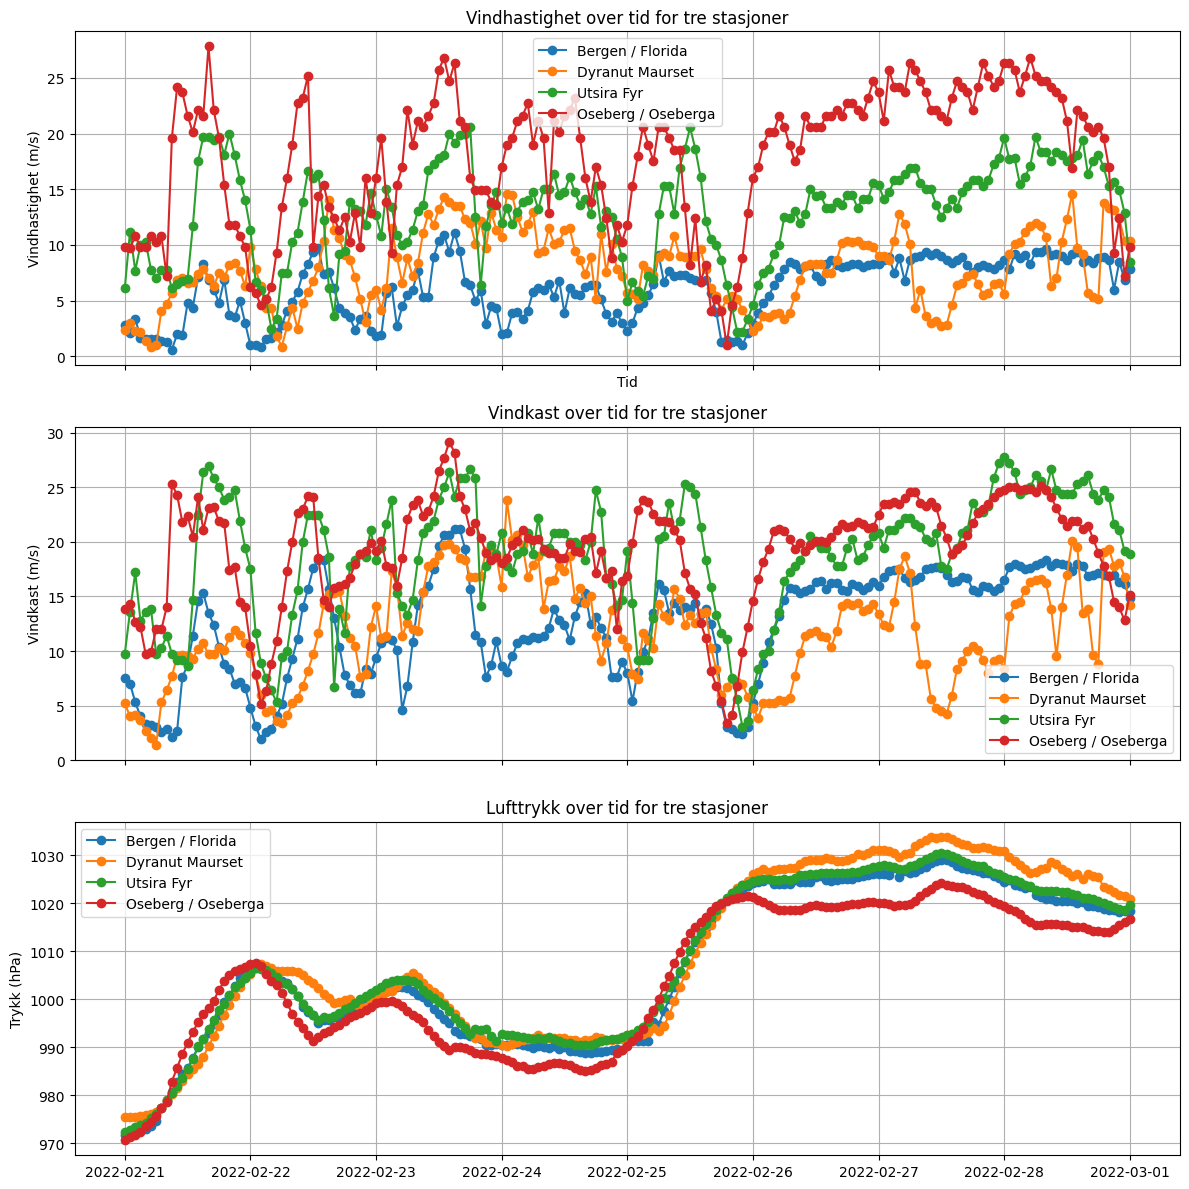

In [496]:
fig, axs = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
# 1. Vindhastighet (wspd)
for sid in station_ids:
    df_station = hourly_data[sid]
    axs[0].plot(df_station.index, df_station['wspd'], marker='o', label=selected_stations.loc[sid, 'name'])

axs[0].set_xlabel('Tid')
axs[0].set_ylabel('Vindhastighet (m/s)')
axs[0].set_title('Vindhastighet over tid for tre stasjoner')
axs[0].legend()
axs[0].grid(True)

# 2. Vindkast (wpgt)
for sid in station_ids:
    df_station = hourly_data[sid]
    axs[1].plot(df_station.index, df_station['wpgt'], marker='o', label=selected_stations.loc[sid, 'name'])
axs[1].set_ylabel('Vindkast (m/s)')
axs[1].set_title('Vindkast over tid for tre stasjoner')
axs[1].legend()
axs[1].grid(True)

# 3. Lufttrykk (pres)
for sid in station_ids:
    df_station = hourly_data[sid]
    axs[2].plot(df_station.index, df_station['pres'], marker='o', label=selected_stations.loc[sid, 'name'])
axs[2].set_ylabel('Trykk (hPa)')
axs[2].set_title('Lufttrykk over tid for tre stasjoner')
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()



## 🔹 Del 1: Bruk av numerisk derivasjon
I denne delen skal du bruke numerisk derivasjon for å undersøke hvordan vindhastighet endrer seg over tid.

**Oppgave:**

**1.** Lag egne Python-funksjoner som beregner den numeriske deriverte (endringsrate) for vindhastighet basert på tidsseriedataene.
- Implementer foroverdifferanse og sentraldifferanse.
- Funksjonene skal ta inn to lister eller arrays: én for tid og én for vindhastighet.

**2.** Test funksjonene dine med en kjent funksjon.

**3.** Plott de numeriske deriverte for vindhastighet for en av stasjonene: Bruk samme figur for å vise både foroverdifferanse og sentraldifferanse. Merk aksene tydelig og legg til en forklarende figurtekst.

**3.** Diskuter forskjellene mellom de to metodene i figuren.

**(Valgfritt)** Glatt dataserien før derivasjon: eksempel _df['gliding_mean'] = df['value'].rolling(window=3).mean()_, se også https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.rolling.html




In [497]:
# Definerer foroverdifferanse.
def for_dif(x,y):
    dx = abs(x[1]-x[0])

    #Tar den høyrederiverte i alle punkter utenom det siste, hvor dette ikke er mulig.
    a = (y[1:]-y[:-1])/dx

    # Tar den venstrederiverte i siste punkt.
    b = np.array([(y[len(y)-2]-y[len(y)-1])/(-dx)])

    y = np.concatenate((a,b))

    return y

# Definerer sentraldifferanse
def sent_dif(x,y):
    dx = abs(x[1]-x[0])

    # Tar den høyrederiverte i første punkt.
    a = np.array([(y[1]-y[0])/dx])

    # Tar den sentralderiverte i alle punkt utenom det første og det siste.
    b = (y[2:]-y[:-2])/(2*dx)

    # Tar den venstrederiverte i siste punkt.
    c = np.array([(y[len(y)-2]-y[len(y)-1])/(-dx)])

    # Setter uttrykkene sammen til en liste.
    y = np.concatenate((a,b,c))

    return y

# Sampler en funksjon f med samplingshastighet 0.01 fra 0 til og med 2.
def f_adapt(f):
  x = np.arange(0,2.01,0.01)
  y = f(x)
  return x,y

x,y=f_adapt(np.exp)
# Kalkulerer den foroverderiverte av samplet eksponensialfunksjon i 1.
print(for_dif(x,y)[101])
# Kalkulerer den sentralderiverte av samplet eksponensialfunksjon i 1.
print(sent_dif(x,y)[101])

2.7593748947381425
2.7456467752626335


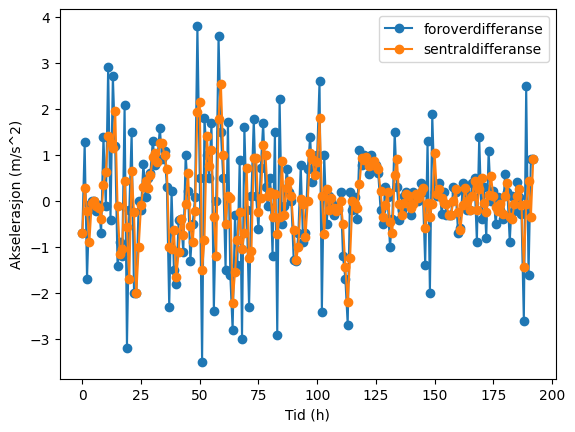

In [498]:
start_time = datetime(2022, 2, 21) # Start date: February 21, 2022
end_time = datetime(2022, 3, 1) # End date: March 1, 2022

s = hourly_data['01317']['wspd'] # Gir tidspunkt og vindfart ifra Bergen / Florida.
tidspunkt = s.index # Tidspunkter
vindhastighet = s.values # Tilsvarende vindhastighet gitt i m/s.

timer = list(range(len(tidspunkt))) # Gjør om 'tidspunkt' gitt i dato om til timer ifra start.

# Tar den foroverderiverte av vindhastigheten.
h_der = for_dif(timer,vindhastighet)
# Tar den sentralderiverte av vindhastigheten.
s_der = sent_dif(timer,vindhastighet)

# Plotter den forover og sentralderiverte av vindhastighet.
plt.plot(timer,h_der, marker = 'o', label = 'foroverdifferanse')
plt.plot(timer,s_der, marker = 'o', label = 'sentraldifferanse')
plt.xlabel("Tid (h)")
plt.ylabel("Akselerasjon (m/s^2)")
plt.legend()
plt.show()

Den sentralderiverte gir mer samlede datapunkter. Mer konkret, så gir den foroverderiverte og sentralderiverte nesten samme verdig når forandringen i vindhastighet er lav. Når forandring i vindhastighet er høyere gir den høyrederiverte mye større utslag en hva den sentralderiverte gjør. Dette kommer av at når en approksimasjon av den høyrederiverte blir høy, vil som regel den tilsvarende approksimasjonen av den venstrederiverte bli lav, og siden den sentralderiverte kan sees på som gjennomsnittet av den venstre og høyrederiverte vil den sentralderiverte som regel være lavere en den høyrederiverte, og som oftest nærmere den ekte deriverte.

## 🔹 Del 2: Ikke-lineær ligning
Vindkraft er energi som utvinnes fra bevegelsen i luftmassene. Når vinden blåser gjennom rotorbladene på en vindturbin, overføres noe av vindens kinetiske energi til rotoren, som igjen driver en generator og produserer elektrisk kraft.

Effekten som kan hentes ut fra vinden, er gitt ved formelen:
$$P(v) = \frac{1}{2} \cdot \rho \cdot A \cdot C_p \cdot v^3$$

I oppgaven bruk:
- $ \rho $ er luftens tetthet (kg/m³), bruk: $ \rho = 1.225 \text{ kg/m}^3 $
- $ A $ er arealet vinden treffer (arealet av rotoren, $A = \pi r^2$), bruk: $ r = 40 \text{ m} \Rightarrow A = \pi r^2 $
- $ C_p $ er effektkoeffisienten, som beskriver hvor stor andel av vindens energi som faktisk kan omdannes til elektrisitet (teoretisk maksimum er Betz-grensen, ca. 0.59, men praktisk ofte 0.4), bruk $ C_p = 0.4 $
- $ v $ er vindhastigheten (m/s)

Formelen viser at effekten øker med tredje potens av vindhastigheten, noe som betyr at små endringer i vind gir store utslag i effekt.

**Oppgave:** Finn vindhastigheten som gir en effekt på 500 kW. Bruk Halveringsmetoden-, Newton- og Sekant-metodene. Sammenlign dine resultater med _scipy.optimize.fsolve_ og finn feilen for metodene.

In [499]:
# Her definerer jeg effekt ut ifra vindhastighet.
def P(v):
  ro = 1.225
  A = np.pi*(40**2)
  Cp = 0.4
  kW = (1/2)*ro*A*Cp*(v**3)/1000
  return kW

# Definerer den deriverte av P med hensyn på v.
def P_norm_der(v):
  ro = 1.225
  A = np.pi*(40**2)
  Cp = 0.4
  kW = (3/2)*ro*A*Cp*(v**2)/1000
  return kW

# Definerer funksjonen f(v)=P(v)-500.
def P_norm(v):
  return P(v)-500

# Finner interval hvor P(v)-500 skifter fortegn ved gjett.
#print(P_norm(-5))
#print(P_norm(10))

# Lager funksjon som approksimerer f(x)=0 ved bruk av Halveringsmetoden.
def halv(f,a,b,k):
  for i in range(k):
    m = (a+b)/2
    if f(m)*f(a) <= 0:
      b = m
    else:
      a = m
  return m

# Lager funksjon som approksimerer f(x)=0 ved bruk av Newtons metode.
def newton(f,f_der,x,k):
  for i in range(k):
      x = x-(f(x)/f_der(x))
  return x

# Lager funksjon som approksimerer f(x)=0 ved bruk av sekantmetoden.
def secant(f,x0,x1,k):
  for i in range(k):
    x2=x1-((x1-x0)/(f(x1)-f(x0)))*f(x1)

    x0 = x1
    x1 =x2

  return x2

# Sammenligner approksimasjonsmetodene med scipy.optimize.fsolve().
for i in range(1,11):
  x = halv(P_norm,-5,10,i)
  y = newton(P_norm,P_norm_der,10,i)
  z = secant(P_norm,1/4,10,i)
  c = scipy.optimize.fsolve(P_norm,10)[0]
  print("Feil etter", i, "itterasjoner:")
  print("x =",x,"y =",y,"z =",z)
  print("Halveringsmetoden:",abs(P(x)-P(c)))
  print("Newtons metode:",abs(P(y)-P(c)))
  print("Sekantmetoden:",abs(P(z)-P(c)))
  print("")




Feil etter 1 itterasjoner:
x = 2.5 y = 8.020025026291627 z = 4.2084827094453425
Halveringsmetoden: 480.75774499676254
Newtons metode: 135.2769679092802
Sekantmetoden: 408.2063622022745

Feil etter 2 itterasjoner:
x = 6.25 y = 7.450759061514194 z = 6.282811081809854
Halveringsmetoden: 199.33976557441423
Newtons metode: 9.374850560190964
Sekantmetoden: 194.5796693560422

Feil etter 3 itterasjoner:
x = 8.125 y = 7.405049598444011 z = 8.172191680521221
Halveringsmetoden: 160.5505350330119
Newtons metode: 0.05739590797247729
Sekantmetoden: 172.12735840157404

Feil etter 4 itterasjoner:
x = 7.1875 y = 7.404766284602599 z = 7.285341778952577
Halveringsmetoden: 42.733365967987254
Newtons metode: 2.195913452851528e-06
Sekantmetoden: 23.804012180708526

Feil etter 5 itterasjoner:
x = 7.65625 y = 7.404766273762449 z = 7.393086576514408
Halveringsmetoden: 52.693373748995896
Newtons metode: 1.1368683772161603e-13
Sekantmetoden: 2.3622523382539384

Feil etter 6 itterasjoner:
x = 7.421875 y = 7.40476

## 🔹 Del 3: Numerisk integrasjon, beregn potensiel energiproduksjon.


I denne oppgaven skal du selv kode opp numeriske integrasjonsmetoder for å beregne total potensiell energi produsert av vindkraft for de fire utvalgte stasjonene i perioden.

**Oppgave:**
1. Skriv dine egne Python-funksjoner for numerisk integrasjon med:
    - Trapesmetoden
    - Midtpunktsmetoden
    - Simpsons metode (forutsetter partall antall intervaller)
2. Test funksjonene dine på et enkelt datasett der du kjenner fasiten, for å sjekke at de gir riktige resultater. En mulighet er å bruke en funksjon du kjenner integralet til.
3. For hver av de fire stasjonene, bruk vindhastighetsdataene til å beregne effekt $P(v)$ for hver time, og integrer effekten over perioden med alle tre metodene.
4. Sammenlign resultatene fra de ulike metodene og diskuter eventuelle forskjeller.
5. Kan du forklare eventuelle forskjeller mellom stasjonene.

**Tips:**   
- Husk å bruke riktig tidsenhet (timer) i integrasjonen slik at du får energien i kWh.
- Du kan bruke `hourly_data[sid]['wspd']` for vindhastighet (i m/s) og `hourly_data[sid].index` for tidspunkter.



In [500]:
# Integrerer f ved trapesmetoden.
def Trapes(f,a,b):
  int = ((b-a)/2)*(f(a)+f(b))
  return int

# Integrerer f ved midtpunktsmetoden
def Midtpunkt(f,a,b):
  int = (b-a)*f((a+b)/2)
  return int

# Integrerer f ved simpsons metode.
def Simpson(f,a,b):
  int = ((b-a)/6)*(f(a)+4*f((a+b)/2)+f(b))
  return int

# Tester integrasjonsmetodene på cos(x) fra 0 til pi, forventet svar er 0.
def f(x):
  return np.cos(x)

a = 0
b = np.pi

print(Trapes(f,a,b))
print(Midtpunkt(f,a,b))
print(Simpson(f,a,b))
# Metodene gir svært nøyaktige resultater. Svaret blir vesentlig mye verre hvis man øker distansen mellom a og b.


0.0
1.9236706937217898e-16
1.1626228326695438e-16


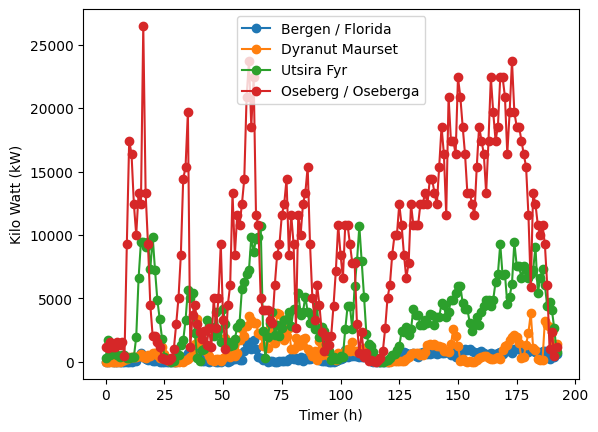

Bergen / Florida
Trapes: 82591.36186989535 kWh
Midtpunkt: 78981.37076513187 kWh
Simpson: 80184.70113338633 kWh

Dyranut Maurset
Trapes: 172922.2901228799 kWh
Midtpunkt: 182384.8872579845 kWh
Simpson: 179230.6882129496 kWh

Utsira Fyr
Trapes: 720819.681823629 kWh
Midtpunkt: 687942.9525925395 kWh
Simpson: 698901.862336236 kWh

Oseberg / Oseberga
Trapes: 1816424.713732369 kWh
Midtpunkt: 1750182.7862716904 kWh
Simpson: 1772263.4287585823 kWh



In [501]:
timer = list(range(len(tidspunkt))) # Gjør om 'tidspunkt' gitt i dato om til timer ifra start.

# Plotter totalt effekt per stasjon.
for sid in station_ids:
  vindhastighet = hourly_data[sid]['wspd'].values
  effekt = P(vindhastighet)
  plt.plot(timer,effekt, marker = 'o', label = selected_stations.loc[sid, 'name'])
plt.xlabel("Timer (h)")
plt.ylabel("Kilo Watt (kW)")
plt.legend()
plt.show()

# Kalkulerer arbeid per værstasjon ved hjelp av de ulike integrasjonsmetodene.
for sid in station_ids:
  intervaller = range(0,191,2)
  A_Trapes = 0
  A_Midtpunkt = 0
  A_Simpson = 0
  vindhastighet = hourly_data[sid]['wspd'].values
  effekt = P(vindhastighet)

  # Gjør om effekt fra en liste til en funksjon av tid.
  def eff(h):
    return effekt[int(h)]

  # Kalkulerer integral av effekt over de første 190 timene
  # ved bruk av trapes-, midtpunkt- og simpsons metode.
  for i in intervaller:
    A_Trapes += Trapes(eff,i,i+2)
    A_Midtpunkt += Midtpunkt(eff,i,i+2)
    A_Simpson += Simpson(eff,i,i+2)

  print(selected_stations.loc[sid, 'name'])
  print("Trapes:",A_Trapes, "kWh")
  print("Midtpunkt:",A_Midtpunkt, "kWh")
  print("Simpson:",A_Simpson, "kWh")
  print("")

4. Da intervallengden valgt er på 2 timer over en total tid på 190 timer vil alle integrasjonsmetodene gi like svar, som man også ser i utregningene. Simpsons metode forventes å gi mest nøyaktig svar, men i disse tilfellene er alle svarene svært like. Implementasjonen min gjør det vanskelig å forandre steglengde på intervallene, så det er upraktisk å teste ut nøyaktighet ved variasjon av steglengde, noe jeg vil ta til betraktning i fremtidige implementasjoner.

5. Værstasjoner som står nært havet vil oppleve sterkere og mer stabil vind enn en stasjon som er plasert i en dal eller mellom fjell. Da effekt er proposjonal med vindhastighet opphøyd i tredje vil små forskjelliger i vindhastighet utgjøre store forskjeller i effekt. Så selv om utslag i effekt er drastisk forskjellig for to værstasjoner trenger det ikke å bety enormt stor forskjell i vindhastighet, men en merkbar forskjell.

## 🔹 Del 4: Interpolasjon
Her skal du:

1. Ta ut hvert tredje datapunkt fra vindhastighetsserien.
2. Lag to interpolasjonsrutiner: én med Lagrange-polynomer og én med splines.
3. Interpoler vindhastigheten for alle tidspunkter mellom punktene, og sammenlign med de faktiske målingene.
4. Plott både de opprinnelige dataene, de utvalgte punktene og de to interpolerte kurvene. Forklar hvorfor du har valgt å presentere dem på denne måten.
5. For en av stasjonene, bruke delte differanser for å se om feilen endrer seg for de to første utelatte punktene i tidsserien hvis du legger til nye data punkter fra tidsserien med hvert tredje datapunkt.  

**Tips:**  
- Beregn og vis gjerne feilen (f.eks. RMSE) mellom de interpolerte verdiene og de faktiske målingene.

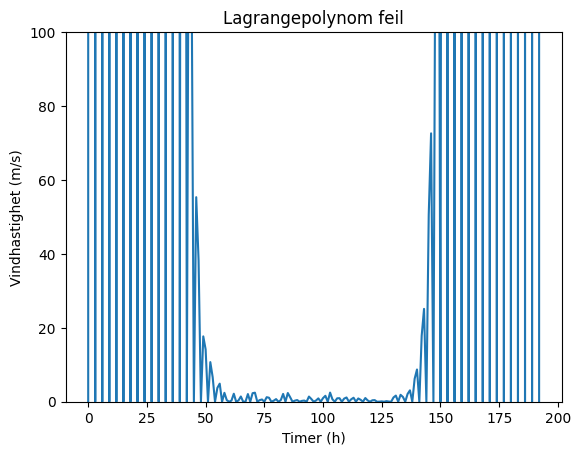

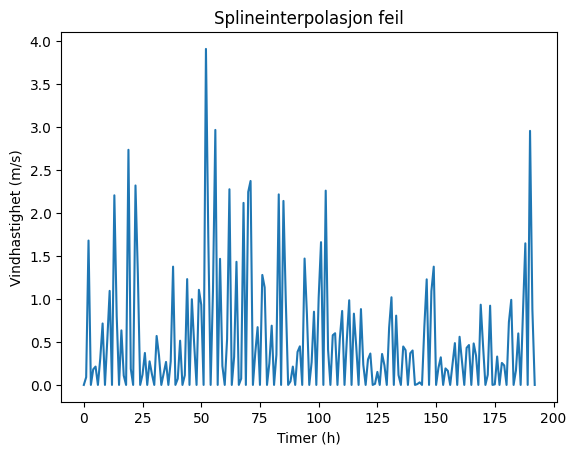

In [502]:
vindhastighet = hourly_data['01317']['wspd'].values # Henter vindhastighetsdata fra Bergen / Florida.
hver_tredje = vindhastighet[::3] # Plukker ut hvert tredje datapunkt fra vindhastighetsserien.
tid = list(range(len(vindhastighet)))
tid_tredje = tid[::3] # Plukker ut hver tredje time ifra tidsaksen.

# Lager Lagrange og spline polynomene. Skulle de implementeres selv?
lagrange_polynom = interp.BarycentricInterpolator(tid_tredje,hver_tredje)

spline_polynom = interp.CubicSpline(tid_tredje,hver_tredje)

# Finner de interpolerte verdiene i punktene vi fjernet.
lagrange_interp = lagrange_polynom(tid)

spline_interp = spline_polynom(tid)

# Sammenligner interpolasjoner med faktisk vindhastighet.
lagrange_feil = abs(vindhastighet-lagrange_interp)
spline_feil = abs(vindhastighet-spline_interp)

# Plotter feil ved Lagrangepolynomet i forhold til målt vindhastighet.
plt.plot(tid,lagrange_feil)
plt.title("Lagrangepolynom feil")
plt.ylim(0,100)
plt.xlabel("Timer (h)")
plt.ylabel("Vindhastighet (m/s)")
plt.show()

# Plotter feil ved spline interpolasjon i forhold til målt vindhastighet.
plt.plot(tid,spline_feil)
plt.title("Splineinterpolasjon feil")
plt.xlabel("Timer (h)")
plt.ylabel("Vindhastighet (m/s)")
plt.show()




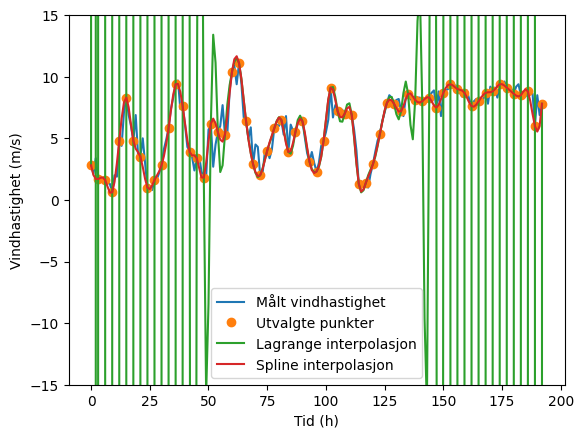

In [503]:
# Plotter vindhastighet, den mindre mengden utvalgte punkter, og interpolasjonspolynomene.
plt.plot(tid,vindhastighet, label = 'Målt vindhastighet')
plt.plot(tid_tredje,hver_tredje, 'o', label = 'Utvalgte punkter')
plt.plot(tid,lagrange_polynom(tid), label = 'Lagrange interpolasjon')
plt.plot(tid,spline_polynom(tid), label = 'Spline interpolasjon')
plt.xlabel('Tid (h)')
plt.ylabel('Vindhastighet (m/s)')
plt.ylim(-15,15)
plt.legend()
plt.show()

Plottet har blitt bregrenset til å kun vise $|y|\leq 20$ ettersom Lagrengepolynomet får så høye verdier ut imot kantene at man ikke kan se de andre grafene. De utvalgte punktene vises som faktiske punkter, for å tydelig se punktene som definerer interpolasjonspolynomene. Målt vindhastighet vises som en linje for å gjøre utvalgte punkter tydelige.

## 🔹 Del 5: Lineær modelltilpasning

For hver stasjon, plott et spredningsdiagram (scatterplot) mellom middelvind (`wspd`) og vindkast (`wpgt`), og tilpass en rett linje (lineær modell) med minste kvadraters metode (least squares). Vis både datapunktene og den tilpassede linjen i figuren. Hvor god er en slik model for de fire stasjonene?

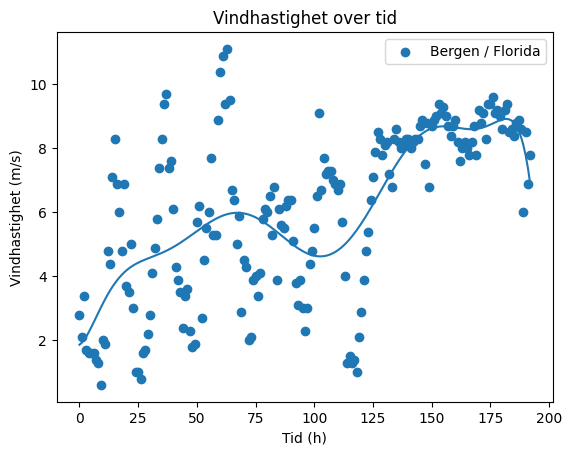

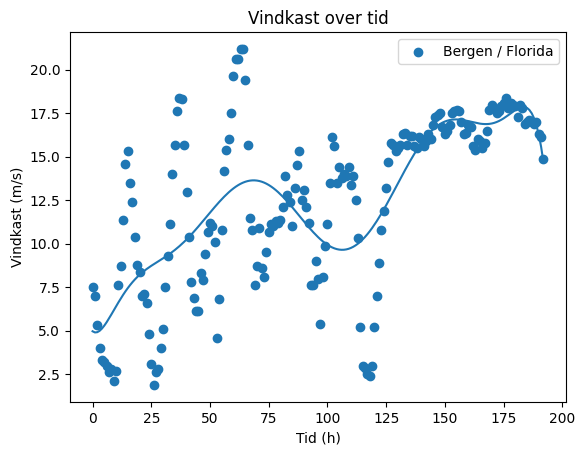

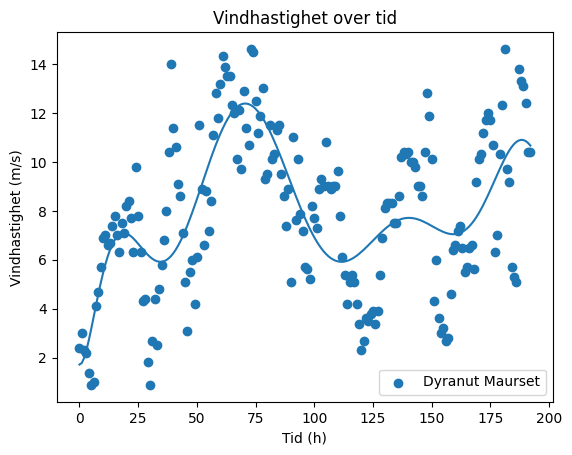

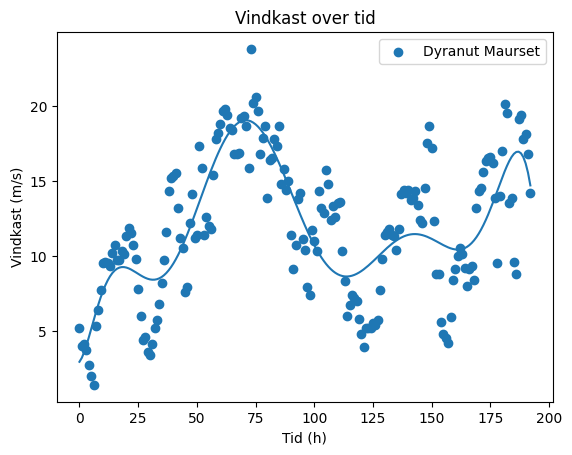

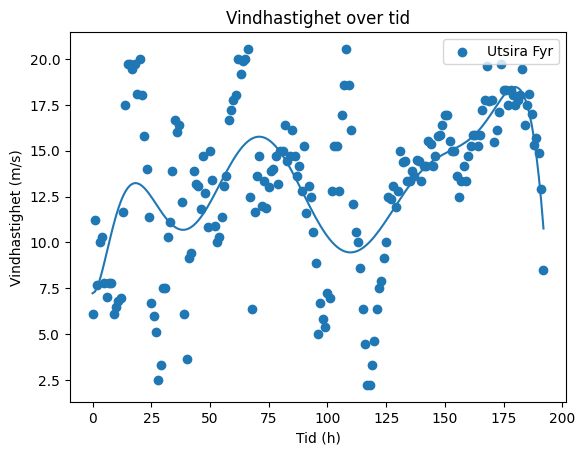

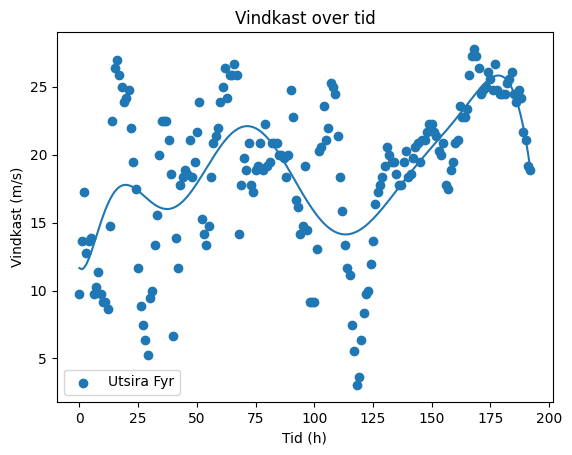

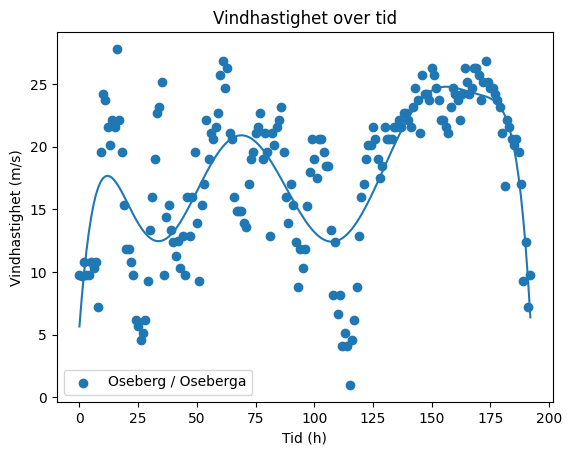

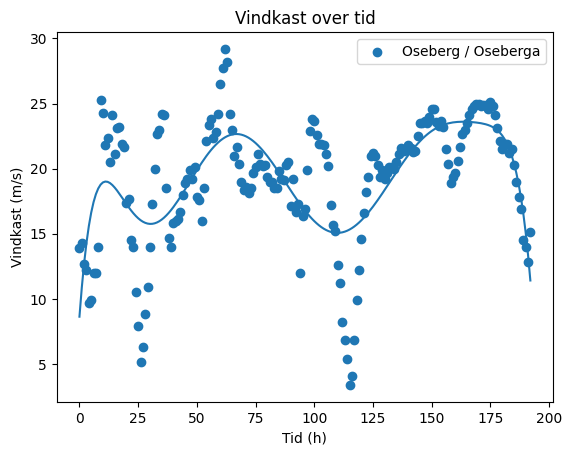

In [504]:
for sid in station_ids:
  vindhastighet = hourly_data[sid]['wspd'].values
  vindkast = hourly_data[sid]['wpgt'].values
  tid = list(range(len(vindhastighet)))

  # Bruker minste kvadraters metode for å tilnerme vindhastighet og vindkast over tid med et polynom av grad 10.
  koeff_1 = np.polyfit(tid, vindhastighet, deg=10)
  p_1 = np.poly1d(koeff_1)

  koeff_2 = np.polyfit(tid, vindkast, deg=10)
  p_2 = np.poly1d(koeff_2)

  plt.scatter(tid,vindhastighet, label = selected_stations.loc[sid, 'name'])
  plt.plot(tid,p_1(tid))
  plt.title("Vindhastighet over tid")
  plt.xlabel("Tid (h)")
  plt.ylabel("Vindhastighet (m/s)")
  plt.legend()
  plt.show()

  plt.scatter(tid,vindkast, label = selected_stations.loc[sid, 'name'])
  plt.plot(tid,p_2(tid))
  plt.title("Vindkast over tid")
  plt.xlabel("Tid (h)")
  plt.ylabel("Vindkast (m/s)")
  plt.legend()
  plt.show()

Minste kvadraters metode tilværmer spredningsdiagrammet godt rundt punktene hvor vindkast og vindhastighet holder seg stabile, og funker drastisk værre under store og raske forandringer i vindkast og vindhastighet.

## 🔹 Del 6:  

1. **Oppgave:**  
    a) Sett en maksgrense for vindkast (`wpgt_max`, f.eks. 25 m/s).  
    b) Regn ut hvor mye energi som produseres i perioden dersom turbinen skrus av (dvs. effekt = 0) i alle tidsintervaller der `wpgt` overstiger denne grensen.  
    c) Diskuter hvordan dette påvirker energiproduksjonen sammenlignet med uten grense.

2. **Ekstra utfordring:**  
    Vi kan ikke alltid måle eller forutsi vindkast nøyaktig.  
    a) Kan du bruke modellen som predikerer vindkast (`wpgt`) ut fra middelvind (`wspd`) til å estimere når turbinen bør skrus av, basert på middelvind alene (f.eks. skrus av når predikert gust overstiger grensen).  
    b) Sammenlign energiproduksjonen og diskuter forskjellen mellom å bruke faktisk gust og predikert gust for styring av turbinen.  

**Tips:**  
- Bruk NumPy eller pandas til å sette effekt til 0 der `wpgt` (eller predikert `wpgt`) er over grensen.  
- Visualiser gjerne hvilke tidspunkter turbinen er aktiv/inaktiv.  
- Diskuter usikkerheten ved å bruke en slik modell i praksis.

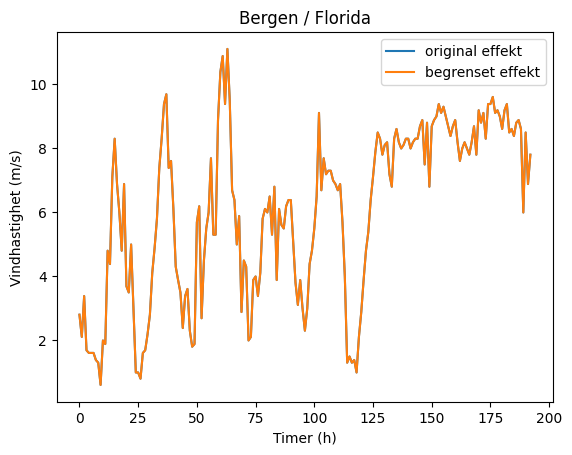

Original produksjon: 80184.70113338633 kWh
Redusert produksjon: 80184.70113338633 kWh
Differanse i energiproduksjon: 0.0 kWh


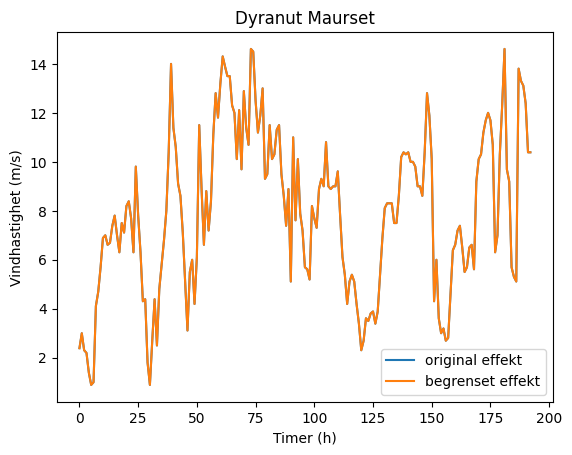

Original produksjon: 179230.6882129496 kWh
Redusert produksjon: 179230.6882129496 kWh
Differanse i energiproduksjon: 0.0 kWh


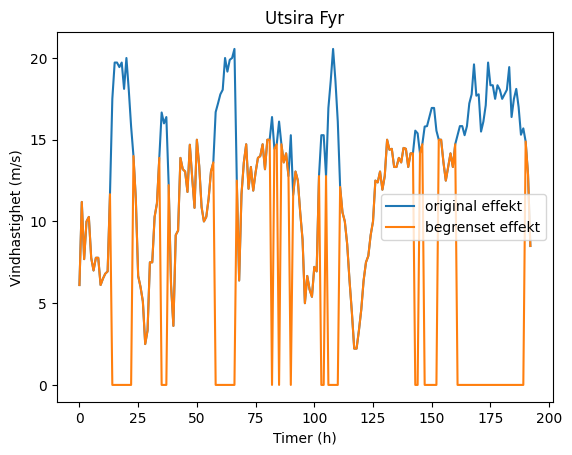

Original produksjon: 698901.862336236 kWh
Redusert produksjon: 252985.87137046346 kWh
Differanse i energiproduksjon: 445915.9909657726 kWh


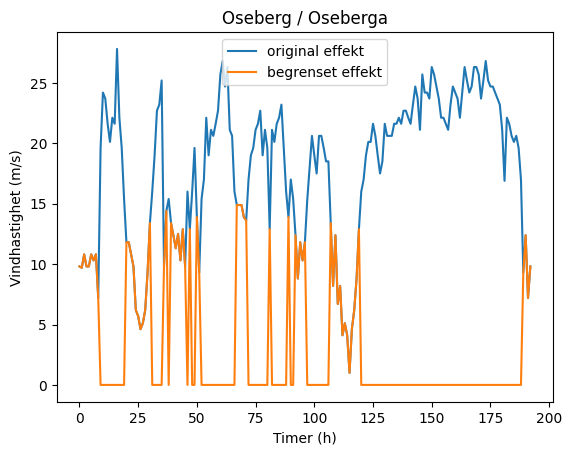

Original produksjon: 1772263.4287585823 kWh
Redusert produksjon: 101212.40197145042 kWh
Differanse i energiproduksjon: 1671051.026787132 kWh


In [505]:
# Plotter effekt og begrenset effekt for hver av værstasjonene.
# Kalkulerer produsert energi, produsert energi ved gitt begrensning og differansen mellom dem.
for sid in station_ids:
  # Lagrer to kopier av vindhastigheten slik at vi kan sammenligne energiproduksjon.
  vindhastighet_orig = hourly_data[sid]['wspd'].values.copy()
  vindhastighet = hourly_data[sid]['wspd'].values.copy()

  tid = list(range(len(vindhastighet)))

  wpgt_max = 15
  vindhastighet[vindhastighet > wpgt_max] = 0 # Setter vindhastighet til null hvis den ligger over wpgt_max

  # Representerer begrenset effekt som en funksjon av tid.
  effekt_ny = P(vindhastighet)
  # Gjør om effekt_ny til en funksjon av tid
  def eff_ny(h):
    return effekt_ny[int(h)]

  # Representerer original effekt som en funksjon av tid.
  effekt_orig = P(vindhastighet_orig)
  # Gjør om effekt_orig til en funksjon av tid
  def eff_orig(h):
    return effekt_orig[int(h)]

  intervaller = range(0,191,2)
  energi1 = 0
  energi2 = 0

  # Kalkulerer energi produsert ved hjelp av Simpsons metode. (energi = integral av effekt over gitt tidsperiode)
  for i in intervaller:
    energi1 += Simpson(eff_ny,i,i+2)
    energi2 += Simpson(eff_orig,i,i+2)

  # Plotter original vindhastighet og redusert vindhastighet for værstasjon sid.
  plt.plot(tid,vindhastighet_orig, label = 'original effekt')
  plt.plot(tid,vindhastighet, label = 'begrenset effekt')
  plt.xlabel("Timer (h)")
  plt.ylabel("Vindhastighet (m/s)")
  plt.title(selected_stations.loc[sid, 'name'])
  plt.legend()
  plt.show()

  # Printer energiproduksjon ved ve to ulike metodene og differansen mellom dem for værstasjon sid.
  print("Original produksjon:", energi2, "kWh")
  print("Redusert produksjon:", energi1, "kWh")
  print("Differanse i energiproduksjon:", energi2-energi1, "kWh")



Siden effekt er proposjonal med vindhastigheten opphøyd i tredje vil vi, ved å skru av turbinen i perioder med sterk vind, ikke produsere energi i de periodene hvor energiproduksjonen er på sitt desidert høyeste. Dette er tydelig i kalkulasjonene gjort, hvor områder hvor vindhastigheten overstiger maksgrensen over lengre tid produserer drastisk mindre energi, som for Oseberg.

En generator koblet til en turbin vil tilføre motstand i systemet, som medfører at turbinen krever mer kraft for å snurre rundt. Hvis generatoren kobles av når vindhastigheten overstiger den gitte grensen, vil turbinen dermed snurre mye raskere enn hva modellen vår tilsier i denne perioden. Når vindhastigheten blir lav nok til at generatoren kobles på vil vi dermed oppleve et midlertidig hopp i energiproduksjon i forohold til hva modellen forutsier.

## 🔹 Del 7: Refleksjon

**Oppgave:**

1. Reflekter over hva du har lært gjennom å løse denne oppgaven.  
    - Hvilke matematiske og programmeringstekniske ferdigheter har du fått brukt og utviklet?
    - Var det noen deler av oppgaven du syntes var spesielt utfordrende eller interessante?

2. Reflekter over bruken av AI i arbeidet med oppgaven.  
    - Har du brukt AI-verktøy (for eksempel ChatGPT, Copilot eller lignende) i arbeidet?  
    - Beskriv konkret hva du har brukt AI til (for eksempel idéutvikling, feilsøking, koding, forklaringer, dokumentasjon osv.).
    - Diskuter fordeler og eventuelle ulemper ved å bruke AI som støtte i slike oppgaver.  
    - Hvordan påvirker bruken av AI din egen læring og forståelse?

1.
Ved å jobbe med denne oppgaven har jeg lært meg hvordan jeg implementerer høyre- og sentralderivasjon på et diskret datasett. Hvordan jeg implementerer trapes-, midtpunkt- og Simpsonsmetode for å integrere både kontinuerlige og diskrete funksjoner.

Jeg har lært om teorien bak Lagrange- og spline interpolasjon og hvordan man bruker pythons scipy bibliotek for å kalkulere disse.

Jeg har forstått teorien bak minste kvadraters metode, og brukt numpys polyfit funksjon, som implementerer minste kvadraters metode, for å tilpasse en kurve til et spredningsdiagram.

Jeg har lært meg litt om hvordan man henter informasjon ut av Pandas dataframes, og hvordan man bruker meteostat for å finne og håndtere ulik informasjon innhentet av diverse værstasjoner rundtom i Norge.

Da jeg har en bakgrunn innen teoretisk matematikk synes jeg det har vært svært interessangt å se hvordan mye av teorien jeg har gått igjennom er direkte motivert av approksimasjonsproblemer. Jeg har ikke jobbet med Python før, og har ikke hatt noe fokus på approksimeringer, så mye av matten jeg har jobbet med har virket abstrakt og lite målrettet. Dette faget har gitt meg et viktig perspekt på hvordan matte faktisk utvikles.

Da jeg har jobbet svært lite med Python synes jeg programeringsbiten har vært utfordrende og har krevet mye tid.

2.
Jeg har brukt Copilot gjennom skrivingen av denne innleveringen. Copilot har blitt brukt for å finne Pythonfunksjoner som gjør det jeg ønsker, og har noen ganger blitt brukt for å finne feil i koden min.

For meg er Coplit svært nyttig da jeg slipper å lete gjennom sidevis av tekst som forklarer hvordan en spesifikk pakke fungerer, og kan heller bli gitt den spesifikke funksjonen som løser problemet mitt. Da jeg alltid prøver å forstå hvordan koden jeg blir gitt fungerer tror jeg ikke dette skaper noe problem for meg, men hvis man direkte kopierer kode man blir gitt av Copilot vil man gå glipp av mye verdifull læring.

Vanlighvis bruker jeg KI som en mer effektiv versjon av Google, som finner det jeg leter etter raskere enn jeg ville gjort det selv. Hvis man beveger seg utenfor denne tankegangen mener jeg man risikerer å få KI'en til å gjøre en job som ville krevet en spesifikk kunskap av en selv, og hvis en KI da gjør jobben vil man ikke forstå at man mangler denne kunnskapen. Det vil også være tilfeller hvor en KI ikke vil kunne hjelpe en, og da trenger man et godt grunnlag for å kunne løse problemet på egenhånd.

KI lar meg lære ting raskere da letetiden for å finne informasjon blir mye mindre. Jeg prøver å ikke la den svekke min forståelse av det jeg lærer om, men det er vanskelig å si nøyaktig hvordan forståelse blir påvirket av bruk av KI.